EVALUACION DE NAIVE BAYES - IMPLEMENTACION "MANUAL"

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix
import pandas as pd
import numpy as np
import algoritmos_clasificacion as t
import importlib
importlib.reload(t)
# Hiperparámetros globales
m_values = [0.5, 1, 5]

def evaluar_naive_bayes(ruta_dataset):

    resultados_bayes = {}

    # Cargar dataset
    S = pd.read_csv(ruta_dataset)

    # Features y target
    
    y = S["dia_lluvioso"]
    X = S.drop(columns=["dia_lluvioso","fecha", "amplitud_carrasco","amplitud_salto","tprom_carrasco","tprom_salto", "fase_lunar", 
                        "int_viento_carrasco_max", "int_racha_viento_carrasco_max", "int_viento_salto_max", "int_racha_viento_salto_max"
                        ])

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for m in m_values:
        print(f"\n=== Evaluando Naive Bayes con m={m} ===")
        
        # Crear modelo
        model = t.NaiveBayesClassifier(m=m)
        
        # Validación cruzada en train
        cv_scores = cross_val_score(model, X_train, y_train, cv=kf)
        
        # Entrenar en todo el train y evaluar en test
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # Métricas en test
        acc_test = accuracy_score(y_test, y_pred)
        recall_test = recall_score(y_test, y_pred, pos_label='si')
        precision_test = precision_score(y_test, y_pred, pos_label='si')
        f1_test = f1_score(y_test, y_pred, pos_label='si')
        cm = confusion_matrix(y_test, y_pred, labels=['si','no'])
        
        # Guardar resultados
        resultados_bayes[m] = {
            "cv_scores": cv_scores,
            "acc_test": acc_test,
            "recall_test": recall_test,
            "precision_test": precision_test,
            "f1_test": f1_test,
            "cm": cm
        }

        # Prints intermedios
        print("Scores por fold:", [round(s,4) for s in cv_scores])
        print(f"Accuracy promedio CV: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
        print(f"Accuracy en test: {acc_test:.4f}")
        print(f"Recall en test: {recall_test:.4f}")
        print(f"Precision en test: {precision_test:.4f}")
        print(f"F1-score en test: {f1_test:.4f}")
        print("Matriz de confusión:")
        print(cm)

    # Resumen final en tabla
    resumen = []
    for m, res in resultados_bayes.items():
        resumen.append({
            "m": m,
            "Accuracy CV (mean)": res["cv_scores"].mean(),
            "Accuracy CV (std)": res["cv_scores"].std(),
            "Accuracy test": res["acc_test"],
            "Recall test": res["recall_test"],
            "Precision test": res["precision_test"],
            "F1 test": res["f1_test"]
        })

    df_resumen = pd.DataFrame(resumen)
    print("\n=== RESUMEN NAIVE BAYES ===")
    print(df_resumen)

    return df_resumen, resultados_bayes


CON SCIKIT LEARN

In [52]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix
from sklearn.naive_bayes import MultinomialNB
import pandas as pd

# Hiperparámetros: al MultinomialNB no le pasamos m, así que solo dejamos alpha
alpha_values = [0.5, 1, 5]

def evaluar_naive_bayes_sklearn(ruta_dataset):
    resultados_bayes = {}

    # Cargar dataset
    S = pd.read_csv(ruta_dataset)

    # Features y target
    X = S.drop(columns=["dia_lluvioso","fecha", "amplitud_carrasco","amplitud_salto","tprom_carrasco","tprom_salto", "fase_lunar", 
                        "int_viento_carrasco_max", "int_racha_viento_carrasco_max", "int_viento_salto_max", "int_racha_viento_salto_max"
                        ])
    y = S["dia_lluvioso"]

    # Convertir categorías a dummies (one-hot)
    X_enc = pd.get_dummies(X.astype(str))

    # Train/test split
    X_train, X_test, y_train, y_test = train_test_split(
        X_enc, y, test_size=0.2, random_state=42, stratify=y
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=42)

    for alpha in alpha_values:
        print(f"\n=== Evaluando MultinomialNB con alpha={alpha} ===")
        
        model = MultinomialNB(alpha=alpha)
        
        # Validación cruzada
        cv_scores = cross_val_score(model, X_train, y_train, cv=kf)
        
        # Entrenar en todo el train y evaluar en test
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # Métricas en test
        acc_test = accuracy_score(y_test, y_pred)
        recall_test = recall_score(y_test, y_pred, pos_label='si')
        precision_test = precision_score(y_test, y_pred, pos_label='si')
        f1_test = f1_score(y_test, y_pred, pos_label='si')
        cm = confusion_matrix(y_test, y_pred, labels=['si','no'])

        resultados_bayes[alpha] = {
            "cv_scores": cv_scores,
            "acc_test": acc_test,
            "recall_test": recall_test,
            "precision_test": precision_test,
            "f1_test": f1_test,
            "cm": cm
        }

        # Prints intermedios
        print("Scores por fold:", [round(s,4) for s in cv_scores])
        print(f"Accuracy promedio CV: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
        print(f"Accuracy en test: {acc_test:.4f}")
        print(f"Recall en test: {recall_test:.4f}")
        print(f"Precision en test: {precision_test:.4f}")
        print(f"F1-score en test: {f1_test:.4f}")
        print("Matriz de confusión:")
        print(cm)

    # Resumen final en tabla
    resumen = []
    for alpha, res in resultados_bayes.items():
        resumen.append({
            "alpha": alpha,
            "Accuracy CV (mean)": res["cv_scores"].mean(),
            "Accuracy CV (std)": res["cv_scores"].std(),
            "Accuracy test": res["acc_test"],
            "Recall test": res["recall_test"],
            "Precision test": res["precision_test"],
            "F1 test": res["f1_test"]
        })

    df_resumen = pd.DataFrame(resumen)
    print("\n=== RESUMEN NAIVE BAYES ===")
    print(df_resumen)

    return df_resumen, resultados_bayes


EVALUACIÓN DE LOS MODELOS

In [53]:
#modelo1_vent1 con implementacion manual
df_res1_1_m, res_bayes1_1_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent1.csv")
print(df_res1_1_m)


=== Evaluando Naive Bayes con m=0.5 ===
Scores por fold: [np.float64(0.7571), np.float64(0.7509), np.float64(0.754), np.float64(0.7509), np.float64(0.7503)]
Accuracy promedio CV: 0.7526 ± 0.0026
Accuracy en test: 0.7512
Recall en test: 0.2311
Precision en test: 0.3954
F1-score en test: 0.2917
Matriz de confusión:
[[ 208  692]
 [ 318 2842]]

=== Evaluando Naive Bayes con m=1 ===
Scores por fold: [np.float64(0.7571), np.float64(0.7506), np.float64(0.754), np.float64(0.7509), np.float64(0.7506)]
Accuracy promedio CV: 0.7526 ± 0.0026
Accuracy en test: 0.7512
Recall en test: 0.2311
Precision en test: 0.3954
F1-score en test: 0.2917
Matriz de confusión:
[[ 208  692]
 [ 318 2842]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.7574), np.float64(0.7509), np.float64(0.7534), np.float64(0.7506), np.float64(0.7506)]
Accuracy promedio CV: 0.7526 ± 0.0026
Accuracy en test: 0.7505
Recall en test: 0.2289
Precision en test: 0.3924
F1-score en test: 0.2891
Matriz de confusión:
[

In [54]:
#modelo1_vent1 con implementacion de scikit
df_res1_1_s, res_bayes1_1_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent1.csv")
print(df_res1_1_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.7574), np.float64(0.7506), np.float64(0.7537), np.float64(0.7503), np.float64(0.7506)]
Accuracy promedio CV: 0.7525 ± 0.0027
Accuracy en test: 0.7505
Recall en test: 0.2289
Precision en test: 0.3924
F1-score en test: 0.2891
Matriz de confusión:
[[ 206  694]
 [ 319 2841]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.7574), np.float64(0.7509), np.float64(0.7534), np.float64(0.75), np.float64(0.7506)]
Accuracy promedio CV: 0.7525 ± 0.0027
Accuracy en test: 0.7507
Recall en test: 0.2289
Precision en test: 0.3931
F1-score en test: 0.2893
Matriz de confusión:
[[ 206  694]
 [ 318 2842]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7589), np.float64(0.7515), np.float64(0.7562), np.float64(0.7515), np.float64(0.7518)]
Accuracy promedio CV: 0.7540 ± 0.0030
Accuracy en test: 0.7507
Recall en test: 0.2267
Precision en test: 0.3923
F1-score en test: 0.2873
Matr

In [55]:
#modelo1_vent2 con implementacion manual
df_res1_2_m, res_bayes1_2_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent2.csv")
print(df_res1_2_m)


=== Evaluando Naive Bayes con m=0.5 ===
Scores por fold: [np.float64(0.7432), np.float64(0.7469), np.float64(0.7512), np.float64(0.7531), np.float64(0.7601)]
Accuracy promedio CV: 0.7509 ± 0.0057
Accuracy en test: 0.7539
Recall en test: 0.1924
Precision en test: 0.3879
F1-score en test: 0.2572
Matriz de confusión:
[[ 173  726]
 [ 273 2888]]

=== Evaluando Naive Bayes con m=1 ===
Scores por fold: [np.float64(0.7429), np.float64(0.7469), np.float64(0.7512), np.float64(0.7531), np.float64(0.7601)]
Accuracy promedio CV: 0.7508 ± 0.0058
Accuracy en test: 0.7542
Recall en test: 0.1924
Precision en test: 0.3888
F1-score en test: 0.2574
Matriz de confusión:
[[ 173  726]
 [ 272 2889]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.742), np.float64(0.7463), np.float64(0.7525), np.float64(0.7531), np.float64(0.7607)]
Accuracy promedio CV: 0.7509 ± 0.0064
Accuracy en test: 0.7542
Recall en test: 0.1913
Precision en test: 0.3883
F1-score en test: 0.2563
Matriz de confusión:


In [56]:
#modelo1_vent2 con implementacion de scikit
df_res1_2_s, res_bayes1_2_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent2.csv")
print(df_res1_2_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.7429), np.float64(0.7469), np.float64(0.7512), np.float64(0.7531), np.float64(0.7601)]
Accuracy promedio CV: 0.7508 ± 0.0058
Accuracy en test: 0.7544
Recall en test: 0.1924
Precision en test: 0.3896
F1-score en test: 0.2576
Matriz de confusión:
[[ 173  726]
 [ 271 2890]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.742), np.float64(0.7463), np.float64(0.7518), np.float64(0.7531), np.float64(0.7607)]
Accuracy promedio CV: 0.7508 ± 0.0064
Accuracy en test: 0.7542
Recall en test: 0.1913
Precision en test: 0.3883
F1-score en test: 0.2563
Matriz de confusión:
[[ 172  727]
 [ 271 2890]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7408), np.float64(0.7469), np.float64(0.7537), np.float64(0.7565), np.float64(0.761)]
Accuracy promedio CV: 0.7518 ± 0.0072
Accuracy en test: 0.7549
Recall en test: 0.1902
Precision en test: 0.3904
F1-score en test: 0.2558
Matr

In [57]:
#modelo1_vent3 con implementacion manual
df_res1_3_m, res_bayes1_3_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent3.csv")
print(df_res1_3_m)


=== Evaluando Naive Bayes con m=0.5 ===
Scores por fold: [np.float64(0.7577), np.float64(0.7586), np.float64(0.7432), np.float64(0.7626), np.float64(0.7622)]
Accuracy promedio CV: 0.7569 ± 0.0071
Accuracy en test: 0.7626
Recall en test: 0.1479
Precision en test: 0.4018
F1-score en test: 0.2163
Matriz de confusión:
[[ 133  766]
 [ 198 2963]]

=== Evaluando Naive Bayes con m=1 ===
Scores por fold: [np.float64(0.7574), np.float64(0.7586), np.float64(0.7432), np.float64(0.7629), np.float64(0.7622)]
Accuracy promedio CV: 0.7569 ± 0.0071
Accuracy en test: 0.7628
Recall en test: 0.1479
Precision en test: 0.4030
F1-score en test: 0.2164
Matriz de confusión:
[[ 133  766]
 [ 197 2964]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.7571), np.float64(0.7586), np.float64(0.7435), np.float64(0.7622), np.float64(0.7619)]
Accuracy promedio CV: 0.7567 ± 0.0069
Accuracy en test: 0.7631
Recall en test: 0.1491
Precision en test: 0.4048
F1-score en test: 0.2179
Matriz de confusión:

In [58]:
#modelo1_vent3 con implementacion de scikit
df_res1_3_s, res_bayes1_3_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent3.csv")
print(df_res1_3_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.7571), np.float64(0.7589), np.float64(0.7432), np.float64(0.7629), np.float64(0.7619)]
Accuracy promedio CV: 0.7568 ± 0.0071
Accuracy en test: 0.7628
Recall en test: 0.1479
Precision en test: 0.4030
F1-score en test: 0.2164
Matriz de confusión:
[[ 133  766]
 [ 197 2964]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.7571), np.float64(0.758), np.float64(0.7435), np.float64(0.7619), np.float64(0.7622)]
Accuracy promedio CV: 0.7566 ± 0.0068
Accuracy en test: 0.7631
Recall en test: 0.1479
Precision en test: 0.4043
F1-score en test: 0.2166
Matriz de confusión:
[[ 133  766]
 [ 196 2965]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7577), np.float64(0.7586), np.float64(0.7435), np.float64(0.7638), np.float64(0.7622)]
Accuracy promedio CV: 0.7572 ± 0.0072
Accuracy en test: 0.7638
Recall en test: 0.1502
Precision en test: 0.4091
F1-score en test: 0.2197
Mat

In [59]:
#modelo1_vent5 con implementacion manual
df_res1_5_m, res_bayes1_5_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent5.csv")
print(df_res1_5_m)


=== Evaluando Naive Bayes con m=0.5 ===
Scores por fold: [np.float64(0.7577), np.float64(0.7638), np.float64(0.7776), np.float64(0.7755), np.float64(0.7712)]
Accuracy promedio CV: 0.7692 ± 0.0074
Accuracy en test: 0.7667
Recall en test: 0.0745
Precision en test: 0.3681
F1-score en test: 0.1240
Matriz de confusión:
[[  67  832]
 [ 115 3046]]

=== Evaluando Naive Bayes con m=1 ===
Scores por fold: [np.float64(0.7577), np.float64(0.7638), np.float64(0.7776), np.float64(0.7755), np.float64(0.7709)]
Accuracy promedio CV: 0.7691 ± 0.0074
Accuracy en test: 0.7667
Recall en test: 0.0745
Precision en test: 0.3681
F1-score en test: 0.1240
Matriz de confusión:
[[  67  832]
 [ 115 3046]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.7568), np.float64(0.7635), np.float64(0.7783), np.float64(0.7761), np.float64(0.7709)]
Accuracy promedio CV: 0.7691 ± 0.0080
Accuracy en test: 0.7665
Recall en test: 0.0745
Precision en test: 0.3661
F1-score en test: 0.1238
Matriz de confusión:

In [60]:
#modelo1_vent5 con implementacion de scikit
df_res1_5_s, res_bayes1_5_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent5.csv")
print(df_res1_5_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.758), np.float64(0.7638), np.float64(0.7779), np.float64(0.7755), np.float64(0.7709)]
Accuracy promedio CV: 0.7692 ± 0.0074
Accuracy en test: 0.7670
Recall en test: 0.0745
Precision en test: 0.3702
F1-score en test: 0.1241
Matriz de confusión:
[[  67  832]
 [ 114 3047]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.758), np.float64(0.7635), np.float64(0.7779), np.float64(0.7758), np.float64(0.7709)]
Accuracy promedio CV: 0.7692 ± 0.0075
Accuracy en test: 0.7670
Recall en test: 0.0745
Precision en test: 0.3702
F1-score en test: 0.1241
Matriz de confusión:
[[  67  832]
 [ 114 3047]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7586), np.float64(0.7641), np.float64(0.7776), np.float64(0.777), np.float64(0.7709)]
Accuracy promedio CV: 0.7696 ± 0.0074
Accuracy en test: 0.7660
Recall en test: 0.0723
Precision en test: 0.3591
F1-score en test: 0.1204
Matri

In [61]:
#modelo1_vent7 con implementacion manual
df_res1_7_m, res_bayes1_7_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent7.csv")
print(df_res1_7_m)


=== Evaluando Naive Bayes con m=0.5 ===
Scores por fold: [np.float64(0.7552), np.float64(0.7749), np.float64(0.7783), np.float64(0.7866), np.float64(0.7736)]
Accuracy promedio CV: 0.7737 ± 0.0103
Accuracy en test: 0.7699
Recall en test: 0.0356
Precision en test: 0.3232
F1-score en test: 0.0641
Matriz de confusión:
[[  32  867]
 [  67 3093]]

=== Evaluando Naive Bayes con m=1 ===
Scores por fold: [np.float64(0.7552), np.float64(0.7749), np.float64(0.7783), np.float64(0.7866), np.float64(0.7739)]
Accuracy promedio CV: 0.7738 ± 0.0103
Accuracy en test: 0.7696
Recall en test: 0.0345
Precision en test: 0.3163
F1-score en test: 0.0622
Matriz de confusión:
[[  31  868]
 [  67 3093]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.7552), np.float64(0.7752), np.float64(0.7783), np.float64(0.7863), np.float64(0.7739)]
Accuracy promedio CV: 0.7738 ± 0.0102
Accuracy en test: 0.7689
Recall en test: 0.0345
Precision en test: 0.3069
F1-score en test: 0.0620
Matriz de confusión:

In [62]:
#modelo1_vent7 con implementacion de scikit
df_res1_7_s, res_bayes1_7_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent7.csv")
print(df_res1_7_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.7552), np.float64(0.7749), np.float64(0.7779), np.float64(0.7863), np.float64(0.7739)]
Accuracy promedio CV: 0.7736 ± 0.0102
Accuracy en test: 0.7694
Recall en test: 0.0345
Precision en test: 0.3131
F1-score en test: 0.0621
Matriz de confusión:
[[  31  868]
 [  68 3092]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.7552), np.float64(0.7752), np.float64(0.7783), np.float64(0.7863), np.float64(0.7739)]
Accuracy promedio CV: 0.7738 ± 0.0102
Accuracy en test: 0.7692
Recall en test: 0.0345
Precision en test: 0.3100
F1-score en test: 0.0621
Matriz de confusión:
[[  31  868]
 [  69 3091]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7549), np.float64(0.7733), np.float64(0.7776), np.float64(0.786), np.float64(0.7743)]
Accuracy promedio CV: 0.7732 ± 0.0102
Accuracy en test: 0.7692
Recall en test: 0.0356
Precision en test: 0.3137
F1-score en test: 0.0639
Mat

In [63]:
#modelo1_vent10 con implementacion manual
df_res1_10_m, res_bayes1_10_m = evaluar_naive_bayes("../Datos_preprocesados/modelo1_vent10.csv")
print(df_res1_10_m)


=== Evaluando Naive Bayes con m=0.5 ===


/home/hezek/.pyenv/versions/3.13.6/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Scores por fold: [np.float64(0.7716), np.float64(0.7789), np.float64(0.7801), np.float64(0.7795), np.float64(0.782)]
Accuracy promedio CV: 0.7784 ± 0.0036
Accuracy en test: 0.7783
Recall en test: 0.0000
Precision en test: 0.0000
F1-score en test: 0.0000
Matriz de confusión:
[[   0  899]
 [   0 3156]]

=== Evaluando Naive Bayes con m=1 ===


/home/hezek/.pyenv/versions/3.13.6/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Scores por fold: [np.float64(0.7716), np.float64(0.7789), np.float64(0.7801), np.float64(0.7795), np.float64(0.782)]
Accuracy promedio CV: 0.7784 ± 0.0036
Accuracy en test: 0.7783
Recall en test: 0.0000
Precision en test: 0.0000
F1-score en test: 0.0000
Matriz de confusión:
[[   0  899]
 [   0 3156]]

=== Evaluando Naive Bayes con m=5 ===
Scores por fold: [np.float64(0.7716), np.float64(0.7789), np.float64(0.7801), np.float64(0.7795), np.float64(0.782)]
Accuracy promedio CV: 0.7784 ± 0.0036
Accuracy en test: 0.7783
Recall en test: 0.0000
Precision en test: 0.0000
F1-score en test: 0.0000
Matriz de confusión:
[[   0  899]
 [   0 3156]]

=== RESUMEN NAIVE BAYES ===
     m  Accuracy CV (mean)  Accuracy CV (std)  Accuracy test  Recall test  \
0  0.5            0.778429           0.003577       0.778298          0.0   
1  1.0            0.778429           0.003577       0.778298          0.0   
2  5.0            0.778429           0.003577       0.778298          0.0   

   Precision test  

/home/hezek/.pyenv/versions/3.13.6/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [69]:
#modelo1_vent10 con implementacion de scikit
df_res1_10_s, res_bayes1_10_s = evaluar_naive_bayes_sklearn("../Datos_preprocesados/modelo1_vent10.csv")
print("print", df_res1_10_s)


=== Evaluando MultinomialNB con alpha=0.5 ===
Scores por fold: [np.float64(0.7887), np.float64(0.7856), np.float64(0.7689), np.float64(0.7702), np.float64(0.7717)]
Accuracy promedio CV: 0.7770 ± 0.0084
Accuracy en test: 0.7765
Recall en test: 0.0100
Precision en test: 0.3462
F1-score en test: 0.0195
Matriz de confusión:
[[   9  890]
 [  17 3143]]

=== Evaluando MultinomialNB con alpha=1 ===
Scores por fold: [np.float64(0.7887), np.float64(0.7856), np.float64(0.7689), np.float64(0.7702), np.float64(0.7717)]
Accuracy promedio CV: 0.7770 ± 0.0084
Accuracy en test: 0.7765
Recall en test: 0.0100
Precision en test: 0.3462
F1-score en test: 0.0195
Matriz de confusión:
[[   9  890]
 [  17 3143]]

=== Evaluando MultinomialNB con alpha=5 ===
Scores por fold: [np.float64(0.7887), np.float64(0.7844), np.float64(0.7689), np.float64(0.7705), np.float64(0.772)]
Accuracy promedio CV: 0.7769 ± 0.0081
Accuracy en test: 0.7761
Recall en test: 0.0100
Precision en test: 0.3214
F1-score en test: 0.0194
Mat

COMPARACIÓN DE ERROR DE LOS MODELOS

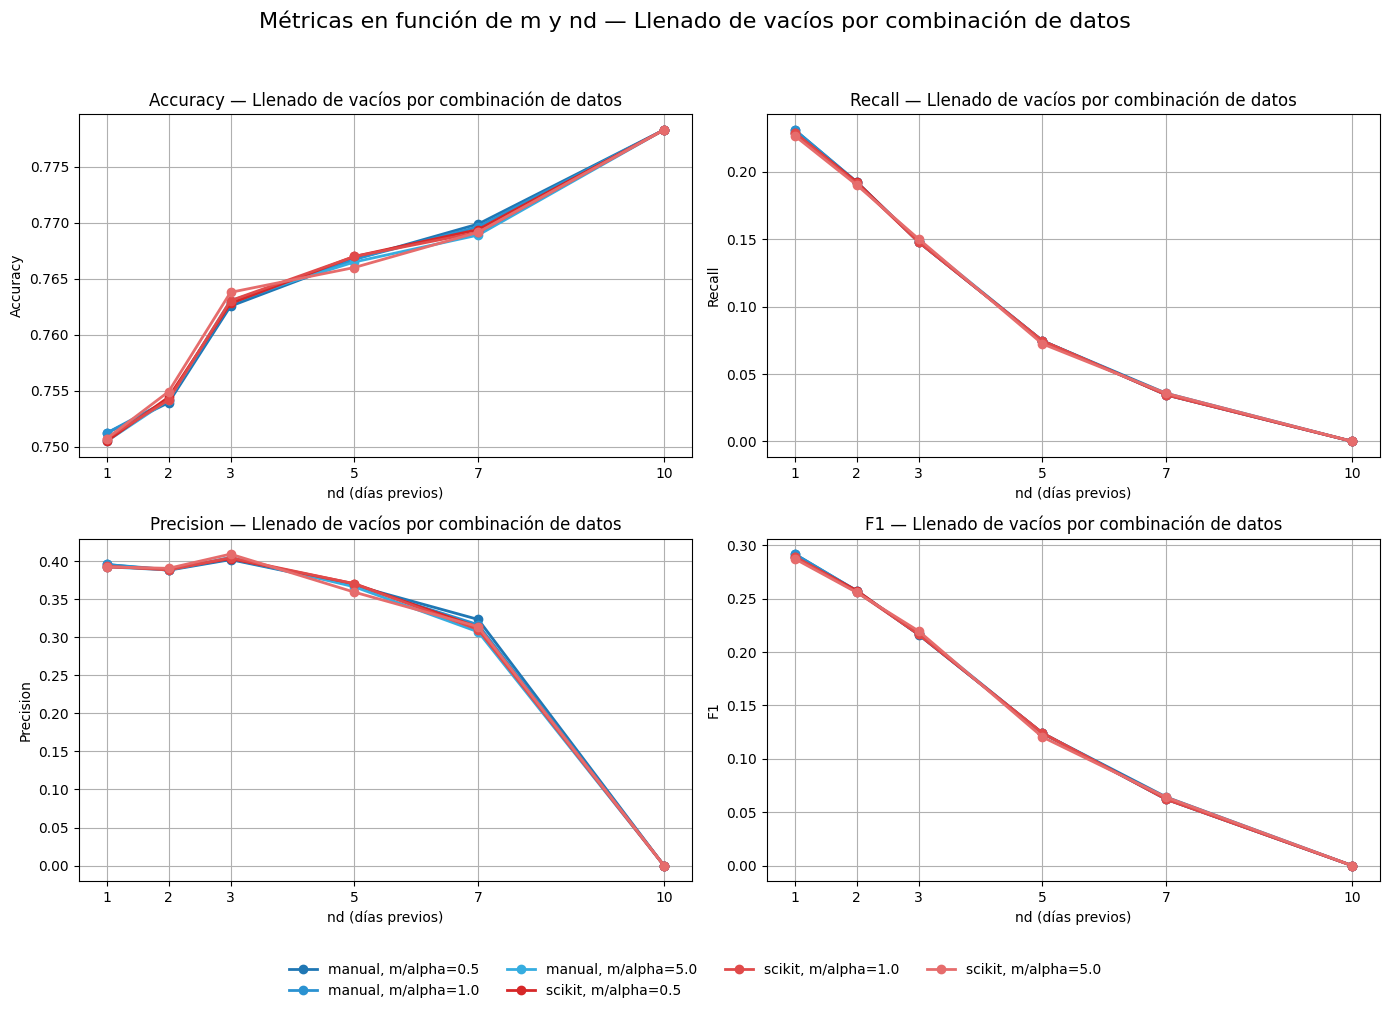

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- Configuración de tus DataFrames ---
dfs_manual_mediana = [df_res1_1_m, df_res1_2_m, df_res1_3_m, df_res1_5_m, df_res1_7_m, df_res1_10_m]
dfs_scikit_mediana = [df_res1_1_s, df_res1_2_s, df_res1_3_s, df_res1_5_s, df_res1_7_s, df_res1_10_s]

nd_values = [1,2,3,5,7,10]

# --- Consolidar resultados en un solo DataFrame ---
rows = []

def procesar_dfs(dfs, imputacion, modelo_type):
    for i, df in enumerate(dfs):
        nd = nd_values[i]
        for _, row in df.iterrows():
            rows.append({
                'imputacion': imputacion,
                'nd': nd,
                'm_alpha': row.get('m', row.get('alpha')),
                'modelo': modelo_type,
                'accuracy': row['Accuracy test'],
                'recall': row['Recall test'],
                'precision': row['Precision test'],  # directamente
                'f1': row['F1 test']
            })

procesar_dfs(dfs_manual_mediana, 'mediana', 'manual')
procesar_dfs(dfs_scikit_mediana, 'mediana', 'scikit')


df_plot = pd.DataFrame(rows)

# --- Función para graficar las 4 métricas en subplots con colores fijos ---
def graficar_subplots_colores_fijos_actualizado(df):
    metricas = ['accuracy','recall','precision','f1']

    # Colores fijos para cada modelo
    colores_manual = ['#1f77b4', '#2a92d1', '#36ade0', '#61c0ff', '#7fc6ff', '#9dd0ff', '#bbe0ff', '#d8f0ff']
    colores_scikit = ['#d62728', '#e04a4a', '#e66c6c', '#eb8f8f', '#f0b3b3', '#f4d6d6', '#f9e0e0', '#fdecec']

    # Mapeo de nombres de imputación para mostrar en gráficos
    nombres_imputacion = {
        'mediana': 'Llenado de vacíos por combinación de datos',
    }

    for imp in df['imputacion'].unique():
        fig, axes = plt.subplots(2, 2, figsize=(14,10))
        axes = axes.flatten()
        df_sub = df[df['imputacion']==imp]

        for idx, metrica in enumerate(metricas):
            ax = axes[idx]
            for modelo in ['manual','scikit']:
                df_model = df_sub[df_sub['modelo']==modelo]
                ms = sorted(df_model['m_alpha'].unique())
                
                for i, m in enumerate(ms):
                    df_m = df_model[df_model['m_alpha']==m].sort_values('nd')
                    color = colores_manual[i] if modelo == 'manual' else colores_scikit[i]
                    ax.plot(df_m['nd'], df_m[metrica], marker='o', linestyle='-', linewidth=2,
                            color=color, label=f"{modelo}, m/alpha={m}")

            ax.set_xlabel("nd (días previos)")
            ax.set_ylabel(metrica.capitalize())
            ax.set_title(f"{metrica.capitalize()} — {nombres_imputacion[imp]}")
            ax.set_xticks(nd_values)
            ax.grid(True)

        # Leyenda centralizada debajo de los subplots
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=10, bbox_to_anchor=(0.5, -0.02))

        # Título principal actualizado
        fig.suptitle(f"Métricas en función de m y nd — {nombres_imputacion[imp]}", fontsize=16)
        plt.tight_layout(rect=[0, 0.05, 1, 0.95])
        plt.show()

# --- Generar gráficos ---
graficar_subplots_colores_fijos_actualizado(df_plot)
